## Task 2:  Implement and Compare the Models

Setup

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from cifar_data import CLASS_NAMES, get_split, load_cifar10, make_test_loader
from models.alexnet import AlexNet
from models.resnet import ResNet18
from train import CHECKPOINT_DIR, Run, count_parameters, evaluate, get_device, run_experiment

RETRAIN = False                      # True = ignore saved checkpoints and train again
FIG_DIR = Path("figures/task2"); FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

device = get_device()
NUM_WORKERS = 2 if device.type == "cuda" else 0

data = load_cifar10()
split = get_split(data["train"])
stats = split["stats"]
print(f"train {len(split['train_ids'])} | val {len(split['val_ids'])} | test {len(data['test'])}")
print("torch", torch.__version__, "| device", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

train 45000 | val 5000 | test 10000
torch 2.15.0+cu132 | device cuda | NVIDIA GeForce RTX 3060 Laptop GPU


## Architectures

Both models follow the A9 tables. Changes from the original ImageNet designs:

- **AlexNet** (Krizhevsky et al., 2012): all convolutions are 3×3 with stride 1 (originally 11×11 stride 4 and 5×5),
  filters 64/192/384/256/256, 2×2 max-pools instead of 3×3 overlapping pools, no local response normalisation,
  FC layers 4096→1024→512→10 instead of 9216→4096→4096→1000. Dropout 0.5 in FC1 and FC2.
- **ResNet-18** (He et al., 2015): 3×3 stride-1 initial convolution instead of 7×7 stride 2, no initial max-pool,
  10 outputs. Four stages of two BasicBlocks (64/128/256/512 channels), projection shortcuts (1×1 conv + BN)
  when the shape changes, global average pooling before a single FC layer.

The table below traces the output shape and parameter count of each top-level layer.

In [2]:
@torch.inference_mode()
def architecture_table(model, size=32):
    rows, hooks = [], []
    for name, layer in model.named_children():
        def hook(module, inputs, output, name=name):
            rows.append({"layer": name, "output shape": tuple(output.shape[1:]),
                         "parameters": sum(p.numel() for p in module.parameters())})
        hooks.append(layer.register_forward_hook(hook))
    model.eval()
    logits = model(torch.zeros(1, 3, size, size, device=device))
    for h in hooks:
        h.remove()
    assert logits.shape == (1, 10)
    table = pd.DataFrame(rows)
    table.loc[len(table)] = {"layer": "TOTAL", "output shape": "", "parameters": count_parameters(model)}
    return table

for name, model_class in [("AlexNet", AlexNet), ("ResNet-18", ResNet18)]:
    print(name)
    display(architecture_table(model_class().to(device)))

AlexNet


,layer,output shape,parameters
0,block1,"(64, 16, 16)",1792
1,block2,"(192, 8, 8)",110784
2,block3,"(384, 8, 8)",663936
3,block4,"(256, 8, 8)",884992
4,block5,"(256, 4, 4)",590080
5,flatten,"(4096,)",0
6,fc1,"(1024,)",4195328
7,relu1,"(1024,)",0
8,dropout1,"(1024,)",0
9,fc2,"(512,)",524800


ResNet-18


,layer,output shape,parameters
0,conv1,"(64, 32, 32)",1728
1,bn1,"(64, 32, 32)",128
2,relu,"(64, 32, 32)",0
3,layer1,"(64, 32, 32)",147968
4,layer2,"(128, 16, 16)",525568
5,layer3,"(256, 8, 8)",2099712
6,layer4,"(512, 4, 4)",8393728
7,avgpool,"(512, 1, 1)",0
8,fc,"(10,)",5130
9,TOTAL,,11173962


## Compute budget and training procedure

- Same budget for both models: **15 epochs × 45,000 images = 675,000 training samples**, batch size 128.
- SGD with momentum 0.9, weight decay 5e-4, cosine learning-rate schedule over the 15 epochs.
- Learning rate: 0.1 for ResNet-18 (BatchNorm makes it stable); 0.01 for AlexNet, which has no
  BatchNorm and diverges at 0.1 (see smoke test).
- No data augmentation in the baselines (it is compared in Task 4).
- **Checkpoint rule:** keep the epoch with the highest validation accuracy. The test set is used once, at the end.
- Seed 42 for weight init, dropout and data order.
Edit the numbers if you choose a different budget. Only keep the "diverges at 0.1" claim if your smoke test actually shows it.


In [ ]:
EPOCHS = 15
BASELINES = {
    "alexnet_baseline":  (AlexNet,  Run("alexnet_baseline",  epochs=EPOCHS, lr=0.01)),
    "resnet18_baseline": (ResNet18, Run("resnet18_baseline", epochs=EPOCHS, lr=0.1)),
}

def train_or_load(model_class, run):
    path = CHECKPOINT_DIR / f"{run.name}_seed{run.seed}.pt"
    if path.exists() and not RETRAIN:
        checkpoint = torch.load(path, map_location=device)
        model = model_class(**run.options).to(device)
        model.load_state_dict(checkpoint["state_dict"])
        print("loaded", path)
        return model, checkpoint["history"], checkpoint["summary"]
    return run_experiment(run, model_class, data, split, device, num_workers=NUM_WORKERS)

models, histories, summaries = {}, {}, {}
for name, (model_class, run) in BASELINES.items():
    models[name], histories[name], summaries[name] = train_or_load(model_class, run)

[1/15] alexnet_baseline | train ce 2.200 acc 0.167 | val ce 1.824 acc 0.334 | 7.9s
[2/15] alexnet_baseline | train ce 1.678 acc 0.368 | val ce 1.483 acc 0.436 | 7.9s
[3/15] alexnet_baseline | train ce 1.425 acc 0.473 | val ce 1.281 acc 0.528 | 7.9s
[4/15] alexnet_baseline | train ce 1.247 acc 0.545 | val ce 1.126 acc 0.585 | 7.9s
[5/15] alexnet_baseline | train ce 1.104 acc 0.600 | val ce 0.994 acc 0.638 | 8.0s
[6/15] alexnet_baseline | train ce 0.968 acc 0.651 | val ce 0.873 acc 0.685 | 8.0s
[7/15] alexnet_baseline | train ce 0.869 acc 0.693 | val ce 0.823 acc 0.714 | 8.0s
[8/15] alexnet_baseline | train ce 0.781 acc 0.723 | val ce 0.764 acc 0.726 | 8.0s
[9/15] alexnet_baseline | train ce 0.696 acc 0.754 | val ce 0.731 acc 0.743 | 8.0s
[10/15] alexnet_baseline | train ce 0.640 acc 0.776 | val ce 0.709 acc 0.752 | 8.0s
[11/15] alexnet_baseline | train ce 0.583 acc 0.796 | val ce 0.670 acc 0.765 | 8.1s
[12/15] alexnet_baseline | train ce 0.544 acc 0.810 | val ce 0.634 acc 0.779 | 8.0s
[

In [10]:
EPOCHS = 40
BASELINES = {
    "alexnet_40":  (AlexNet,  Run("alexnet_40",  epochs=EPOCHS, lr=0.01)),
}

def train_or_load(model_class, run):
    path = CHECKPOINT_DIR / f"{run.name}_seed{run.seed}.pt"
    if path.exists() and not RETRAIN:
        checkpoint = torch.load(path, map_location=device)
        model = model_class(**run.options).to(device)
        model.load_state_dict(checkpoint["state_dict"])
        print("loaded", path)
        return model, checkpoint["history"], checkpoint["summary"]
    return run_experiment(run, model_class, data, split, device, num_workers=NUM_WORKERS)

models, histories, summaries = {}, {}, {}
for name, (model_class, run) in BASELINES.items():
    models[name], histories[name], summaries[name] = train_or_load(model_class, run)

[1/40] alexnet_40 | train ce 2.200 acc 0.167 | val ce 1.824 acc 0.334 | 7.9s
[2/40] alexnet_40 | train ce 1.677 acc 0.369 | val ce 1.479 acc 0.449 | 7.9s
[3/40] alexnet_40 | train ce 1.423 acc 0.473 | val ce 1.300 acc 0.530 | 7.9s
[4/40] alexnet_40 | train ce 1.242 acc 0.547 | val ce 1.115 acc 0.593 | 8.0s
[5/40] alexnet_40 | train ce 1.099 acc 0.603 | val ce 0.992 acc 0.639 | 7.9s
[6/40] alexnet_40 | train ce 0.958 acc 0.656 | val ce 0.851 acc 0.696 | 8.0s
[7/40] alexnet_40 | train ce 0.851 acc 0.699 | val ce 0.818 acc 0.718 | 8.0s
[8/40] alexnet_40 | train ce 0.765 acc 0.731 | val ce 0.748 acc 0.733 | 8.0s
[9/40] alexnet_40 | train ce 0.681 acc 0.762 | val ce 0.711 acc 0.753 | 8.0s
[10/40] alexnet_40 | train ce 0.619 acc 0.785 | val ce 0.666 acc 0.766 | 8.0s
[11/40] alexnet_40 | train ce 0.548 acc 0.811 | val ce 0.699 acc 0.761 | 8.0s
[12/40] alexnet_40 | train ce 0.497 acc 0.828 | val ce 0.605 acc 0.788 | 8.1s
[13/40] alexnet_40 | train ce 0.448 acc 0.845 | val ce 0.615 acc 0.794 | 

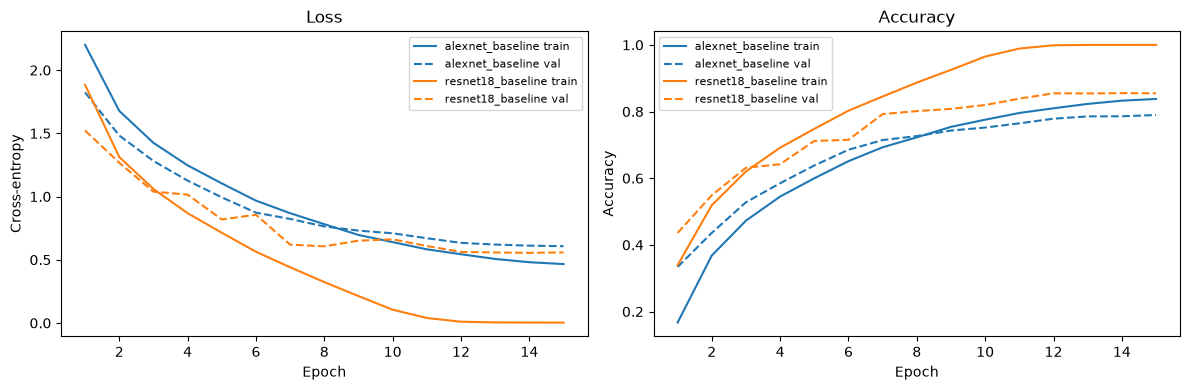

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    h = pd.DataFrame(history)
    for ax, metric in zip(axes, ["ce", "accuracy"]):
        line, = ax.plot(h.epoch, h[f"train_{metric}"], label=f"{name} train")
        ax.plot(h.epoch, h[f"val_{metric}"], "--", color=line.get_color(), label=f"{name} val")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Loss")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curves.png", dpi=150)
plt.show()

In [6]:
comparison = pd.DataFrame(summaries.values()).set_index("run")
comparison["seconds_per_epoch"] = comparison["train_seconds"] / EPOCHS
columns = ["parameters", "best_epoch", "best_val_accuracy", "train_seconds",
           "seconds_per_epoch", "samples_seen", "peak_gpu_mb", "device"]
display(comparison[columns].round(4))
comparison[columns].to_csv(RESULTS_DIR / "task2_baselines.csv")

,parameters,best_epoch,best_val_accuracy,train_seconds,seconds_per_epoch,samples_seen,peak_gpu_mb,device
run,,,,,,,,
alexnet_baseline,6976842,15,0.7896,120.1080,8.0072,675000,269.9443,cuda
resnet18_baseline,11173962,14,0.8552,409.7389,27.3159,675000,797.2183,cuda


## Final test evaluation

Both models and all settings above were fixed using validation data only. The test set is evaluated once here.

In [7]:
test_loader = make_test_loader(data["test"], batch_size=256, num_workers=NUM_WORKERS)
test_rows = []
for name, model in models.items():
    result = evaluate(model, test_loader, stats, device)
    test_rows.append({"run": name, "test_ce": result["ce"], "test_accuracy": result["accuracy"],
                      "best_val_accuracy": summaries[name]["best_val_accuracy"]})
test_table = pd.DataFrame(test_rows).set_index("run")
display(test_table.round(4))
test_table.to_csv(RESULTS_DIR / "task2_test.csv")

,test_ce,test_accuracy,best_val_accuracy
run,,,
alexnet_baseline,0.6176,0.7855,0.7896
resnet18_baseline,0.5774,0.8468,0.8552
